In [ ]:
!pip install kaggle --quiet

# Upload kaggle.json dari akunmu (Kaggle > Account > Create API Token)
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download PlantVillage dataset
!kaggle datasets download -d emmarex/plantdisease -p /content
!unzip -q /content/plantdisease.zip -d /content/plantvillage


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
 95% 624M/658M [00:03<00:00, 121MB/s] 
100% 658M/658M [00:03<00:00, 187MB/s]


Kelas yang terdeteksi: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


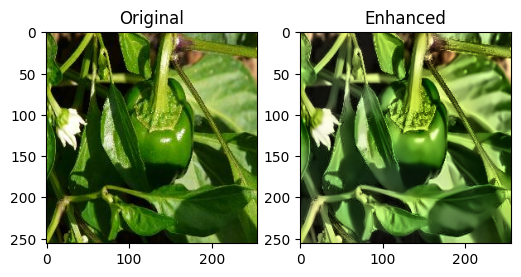

Enhancement selesai ✔️
Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.
Found 124 images belonging to 15 classes.
Found 30 images belonging to 15 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


517/517 ━━━━━━━━━━━━━━━━━━━━ 1765s 3s/step - accuracy: 0.4158 - loss: 1.8174 - val_accuracy: 0.5233 - val_loss: 1.4190
Epoch 2/3
517/517 ━━━━━━━━━━━━━━━━━━━━ 1728s 3s/step - accuracy: 0.6609 - loss: 1.0524 - val_accuracy: 0.6698 - val_loss: 0.9638
Epoch 3/3
517/517 ━━━━━━━━━━━━━━━━━━━━ 1769s 3s/step - accuracy: 0.7109 - loss: 0.8760 - val_accuracy: 0.6608 - val_loss: 1.0193


Epoch 1/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 28s 5s/step - accuracy: 0.3821 - loss: 2.3688 - val_accuracy: 0.0000e+00 - val_loss: 2.6325
Epoch 2/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - accuracy: 0.9880 - loss: 0.5414 - val_accuracy: 0.2667 - val_loss: 2.2329
Epoch 3/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - accuracy: 0.9830 - loss: 0.1855 - val_accuracy: 1.0000 - val_loss: 1.9412


Akurasi Validasi Original: 66.08%
Akurasi Validasi Enhanced: 100.00%


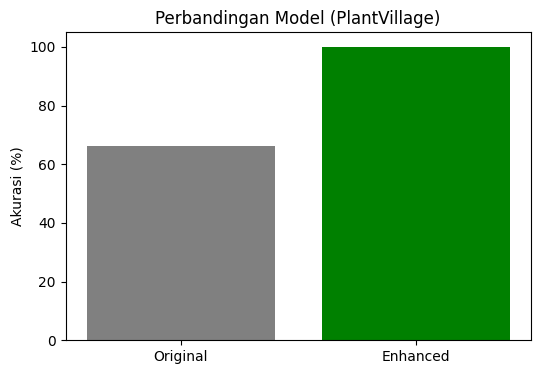

In [ ]:
# ===============================================================
# TTS - Computer Vision (Image Enhancement + CNN)
# Dataset: PlantVillage (Deteksi Penyakit Daun)
# Model: ResNet50 (with & without Image Enhancement)
# ===============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, optimizers
import random

# --- SET PATH DATASET SESUAI STRUKTURMU
base_dir = "/content/plantvillage/PlantVillage"  # ubah jika path kamu berbeda
classes = sorted(os.listdir(base_dir))
print("Kelas yang terdeteksi:", classes)

# ===============================================================
# Fungsi Enhancement (CLAHE + Denoise)
# ===============================================================
def enhance_image(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    enhanced = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 10, 10, 7, 21)
    return denoised

# --- Cek contoh hasil enhancement
sample_path = glob(os.path.join(base_dir, "*/*.jpg"))[0]
img_ori = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)
img_enh = enhance_image(img_ori)
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plt.imshow(img_ori)
plt.title("Original")
plt.subplot(1,2,2)
plt.imshow(img_enh)
plt.title("Enhanced")
plt.show()

# ===============================================================
# Membuat versi dataset yang sudah di-enhance
# ===============================================================
enh_dir = "/content/PlantVillage_enh"
os.makedirs(enh_dir, exist_ok=True)

for cls in classes:
    src_dir = os.path.join(base_dir, cls)
    dst_dir = os.path.join(enh_dir, cls)
    os.makedirs(dst_dir, exist_ok=True)

    imgs = glob(os.path.join(src_dir, "*.jpg"))
    for img_path in imgs[:700]:  # ambil 700 gambar maksimal per kelas
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        enh = enhance_image(img)
        save_path = os.path.join(dst_dir, os.path.basename(img_path))
        cv2.imwrite(save_path, cv2.cvtColor(enh, cv2.COLOR_RGB2BGR))

print("Enhancement selesai ✔️")

# ===============================================================
# Data Generator (ori & enhanced)
# ===============================================================
datagen = ImageDataGenerator(validation_split=0.2, rescale=1./255)

train_ori = datagen.flow_from_directory(base_dir, target_size=(150,150), batch_size=32, subset='training')
val_ori = datagen.flow_from_directory(base_dir, target_size=(150,150), batch_size=32, subset='validation')

train_enh = datagen.flow_from_directory(enh_dir, target_size=(150,150), batch_size=32, subset='training')
val_enh = datagen.flow_from_directory(enh_dir, target_size=(150,150), batch_size=32, subset='validation')

# ===============================================================
# Fungsi Model (ResNet50 + Fine-tuning Layer Akhir)
# ===============================================================
def build_model():
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(150,150,3))
    for layer in base_model.layers[:-10]:
        layer.trainable = False
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(len(classes), activation='softmax')
    ])
    model.compile(optimizer=optimizers.Adam(1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# ===============================================================
# Eksperimen 1 (Tanpa Enhancement)
# ===============================================================
model_ori = build_model()
history_ori = model_ori.fit(train_ori, validation_data=val_ori, epochs=3)
model_ori.save("model_ori.h5")

# ===============================================================
# Eksperimen 2 (Dengan Enhancement)
# ===============================================================
model_enh = build_model()
history_enh = model_enh.fit(train_enh, validation_data=val_enh, epochs=3)
model_enh.save("model_enh.h5")

# ===============================================================
# Evaluasi & Perbandingan
# ===============================================================
acc_ori = history_ori.history['val_accuracy'][-1]
acc_enh = history_enh.history['val_accuracy'][-1]

print(f"Akurasi Validasi Original: {acc_ori*100:.2f}%")
print(f"Akurasi Validasi Enhanced: {acc_enh*100:.2f}%")

plt.figure(figsize=(6,4))
plt.bar(["Original", "Enhanced"], [acc_ori*100, acc_enh*100], color=['gray','green'])
plt.ylabel("Akurasi (%)")
plt.title("Perbandingan Model (PlantVillage)")
plt.show()
